# Laugh vs Choke - AudioCNN v4
שיפורים: Stratified split · Global Avg Pooling · נרמול קלט · Dropout2d · Batch=16 · LR Scheduler · Early Stopping

In [1]:
import os
import json
import random
import numpy as np
from pathlib import Path
from collections import defaultdict

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
PROJECT_DIR   = Path("/content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים")
PROCESSED_DIR = PROJECT_DIR / "processed"

META_PATH      = PROCESSED_DIR / "meta.json"
NORM_PATH      = PROCESSED_DIR / "norm_stats.json"
MANIFEST_PATH  = PROCESSED_DIR / "manifest.json"

with open(META_PATH, "r") as f:
    meta = json.load(f)

with open(NORM_PATH, "r") as f:
    norm_stats = json.load(f)

with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

CHANNEL_NAMES = meta["channels"]
N_CHANNELS    = meta["n_channels"]
HEIGHT, WIDTH = meta["tensor_shape"][1], meta["tensor_shape"][2]

CLASS_NAMES   = ["choking", "laughter"]
NUM_CLASSES   = len(CLASS_NAMES)
class_to_idx  = {name: i for i, name in enumerate(CLASS_NAMES)}

print("Channels:", CHANNEL_NAMES)
print("Number of channels:", N_CHANNELS)
print("Input shape:", (N_CHANNELS, HEIGHT, WIDTH))
print("Classes:", class_to_idx)

print("\nManifest original-file counts:")
for split in ["train", "val", "test"]:
    print(split, manifest["counts"][split])

Channels: ['log_mel', 'harmonic_mel', 'percussive_mel', 'delta', 'delta_delta', 'zcr', 'rms', 'spectral_centroid', 'spectral_rolloff', 'spectral_bandwidth', 'spectral_contrast', 'chroma', 'mfcc', 'tonnetz', 'spectral_flatness', 'f0', 'voiced_prob', 'spectral_flux', 'wide_band_mel', 'rms_periodicity']
Number of channels: 20
Input shape: (20, 128, 128)
Classes: {'choking': 0, 'laughter': 1}

Manifest original-file counts:
train {'choking': 88, 'laughter': 72}
val {'choking': 17, 'laughter': 23}
test {'choking': 34, 'laughter': 25}


In [4]:
def collect_split_samples(split_name):
    split_dir = PROCESSED_DIR / split_name
    samples = []

    for class_name in CLASS_NAMES:
        class_dir = split_dir / class_name
        label = class_to_idx[class_name]

        for file_path in sorted(class_dir.glob("*.npy")):
            samples.append((file_path, label))

    return samples


train_samples = collect_split_samples("train")
val_samples   = collect_split_samples("val")
test_samples  = collect_split_samples("test")


def print_split_summary(split_name, samples):
    counts = {class_name: 0 for class_name in CLASS_NAMES}

    for _, label in samples:
        class_name = CLASS_NAMES[label]
        counts[class_name] += 1

    print(f"{split_name}: {len(samples)} tensors")
    for class_name in CLASS_NAMES:
        print(f"  {class_name}: {counts[class_name]}")


print("\nTensor counts after preprocessing:")
print_split_summary("Train", train_samples)
print_split_summary("Val", val_samples)
print_split_summary("Test", test_samples)


Tensor counts after preprocessing:
Train: 640 tensors
  choking: 352
  laughter: 288
Val: 80 tensors
  choking: 34
  laughter: 46
Test: 59 tensors
  choking: 34
  laughter: 25


## 1. Dataset עם נרמול קלט
נרמול per-sample מייצב את האימון ומקל על המודל

In [5]:
class AudioFeatureDataset(Dataset):
    def __init__(self, samples, norm_stats):
        self.samples = samples

        self.mean = np.array(
            norm_stats["mean"],
            dtype=np.float32
        )[:, None, None]

        self.std = np.array(
            norm_stats["std"],
            dtype=np.float32
        )[:, None, None]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        file_path, label = self.samples[idx]

        x = np.load(file_path).astype(np.float32)

        # Per-channel z-score using TRAIN statistics
        x = (x - self.mean) / self.std

        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(label, dtype=torch.long)
        )
train_dataset = AudioFeatureDataset(
    train_samples,
    norm_stats
)

val_dataset = AudioFeatureDataset(
    val_samples,
    norm_stats
)

test_dataset = AudioFeatureDataset(
    test_samples,
    norm_stats
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

## 2. Multi-Branch Architecture
בדיוק כפי שמתואר בפוסטר — Tonal / Transient / Energy branches

In [6]:
class BranchCNN(nn.Module):
    """
    Branch קטן ומינימליסטי — מותאם לדאטה קטן.
    2 שכבות Conv בלבד + AdaptiveAvgPool → פחות פרמטרים, פחות overfitting.
    """
    def __init__(self, in_channels, out_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Dropout2d(0.3),
            nn.AdaptiveAvgPool2d(1),  # → (batch, 32, 1, 1)
        )
        self.fc = nn.Linear(32, out_dim)

    def forward(self, x):
        x = self.net(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


class MultiBranchAudioCNN(nn.Module):
    """
    Multi-Fusion CNN מינימליסטי — מותאם ל-400 דוגמאות.

    3 branches קטנים (32 dim כל אחד) → Fusion (96) → classifier פשוט.

    Channel indices:
      Tonal:     [0,1,11,12,13,15,16]  log_mel, harmonic_mel, chroma, mfcc, tonnetz, f0, voiced_prob
      Transient: [2,3,4,17,18]         percussive_mel, delta, delta_delta, spectral_flux, wide_band_mel
      Energy:    [5,6,7,8,9,10,14,19]  zcr, rms, centroid, rolloff, bandwidth, contrast, flatness, rms_periodicity
    """
    TONAL_NAMES = [
         "log_mel", "harmonic_mel", "chroma", "mfcc", "tonnetz", "f0", "voiced_prob"
    ]

    TRANSIENT_NAMES = [
        "percussive_mel", "delta", "delta_delta",
        "spectral_flux", "wide_band_mel"
    ]

    ENERGY_NAMES = [
        "zcr", "rms", "spectral_centroid", "spectral_rolloff", "spectral_bandwidth", "spectral_contrast", "spectral_flatness", "rms_periodicity"
    ]

    TONAL_IDX     = [CHANNEL_NAMES.index(name) for name in TONAL_NAMES]
    TRANSIENT_IDX = [CHANNEL_NAMES.index(name) for name in TRANSIENT_NAMES]
    ENERGY_IDX    = [CHANNEL_NAMES.index(name) for name in ENERGY_NAMES]

    def __init__(self, num_classes=2, branch_dim=32):
        super().__init__()
        self.tonal_branch     = BranchCNN(len(self.TONAL_IDX),     branch_dim)
        self.transient_branch = BranchCNN(len(self.TRANSIENT_IDX), branch_dim)
        self.energy_branch    = BranchCNN(len(self.ENERGY_IDX),    branch_dim)

        fusion_in = branch_dim * 3  # 96
        self.classifier = nn.Sequential(
            nn.Linear(fusion_in, 48),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(48, num_classes)
        )

    def forward(self, x):
        t  = self.tonal_branch    (x[:, self.TONAL_IDX,     :, :])
        tr = self.transient_branch(x[:, self.TRANSIENT_IDX, :, :])
        e  = self.energy_branch   (x[:, self.ENERGY_IDX,    :, :])

        fused = torch.cat([t, tr, e], dim=1)  # (batch, 96)
        return self.classifier(fused)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = MultiBranchAudioCNN(num_classes=NUM_CLASSES).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params:,}")


Using device: cuda
Total trainable parameters: 25,058


## 3. Training & Evaluation Functions

In [7]:
# ============================================================
# תשתית אימון משותפת — משמשת את שני המודלים בדיוק באותו אופן.
# המשתנה היחיד בין שתי הריצות הוא אובייקט המודל עצמו. כל השאר
# (loss, optimizer, scheduler, gradient clipping, early stopping,
# מספר epochs, סדר ה-batches, seed) משותף. לכן כל הבדל בביצועים
# ניתן לייחוס לארכיטקטורה בלבד.
# ============================================================
from collections import Counter


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class TrainConfig:
    seed           = 42
    lr             = 5e-4
    weight_decay   = 1e-3
    num_epochs     = 15
    patience       = 8      # early stopping on val_loss
    grad_clip      = 5.0    # applied to BOTH models
    sched_patience = 4
    sched_factor   = 0.5


# ----- loss משוקלל אחד, אותם משקלים לשני המודלים -----
_label_counts = Counter(lbl for _, lbl in train_samples)
_counts = torch.tensor(
    [_label_counts.get(i, 0) for i in range(NUM_CLASSES)], dtype=torch.float
)
class_weights = (_counts.sum() / (NUM_CLASSES * _counts.clamp(min=1))).to(device)
shared_criterion = nn.CrossEntropyLoss(weight=class_weights)

print("Train class counts:",
      {CLASS_NAMES[i]: int(_counts[i]) for i in range(NUM_CLASSES)})
print("Class weights:",
      {CLASS_NAMES[i]: round(class_weights[i].item(), 3) for i in range(NUM_CLASSES)})


def train_one_epoch(model, loader, optimizer, criterion, device, grad_clip=None):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        outputs = model(x)
        loss = criterion(outputs, y)
        loss.backward()
        if grad_clip is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == y).sum().item()
        total += y.size(0)
    return total_loss / max(total, 1), correct / max(total, 1)


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            loss = criterion(outputs, y)
            total_loss += loss.item() * x.size(0)
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    return total_loss / max(total, 1), correct / max(total, 1), all_preds, all_labels


def run_training(model, criterion, cfg, best_path):
    """
    פרוטוקול אימון יחיד שמשמש את שני המודלים בדיוק באותו אופן.
    קריאת set_seed בתחילת הריצה מבטיחה שגם סדר הערבוב של ה-batches
    זהה בין שתי הארכיטקטורות. מחזיר היסטוריית אימון ואת ה-epoch הטוב
    ביותר (לפי val_loss, אותו מודל שנשמר ונטען).
    """
    set_seed(cfg.seed)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=cfg.sched_patience, factor=cfg.sched_factor
    )

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_epoch = 0
    counter = 0

    for epoch in range(cfg.num_epochs):
        tr_loss, tr_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, device, cfg.grad_clip
        )
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion, device)

        hist["train_loss"].append(tr_loss)
        hist["val_loss"].append(va_loss)
        hist["train_acc"].append(tr_acc)
        hist["val_acc"].append(va_acc)

        scheduler.step(va_loss)
        lr_now = optimizer.param_groups[0]["lr"]
        gap = tr_acc - va_acc

        print(
            f"Epoch [{epoch+1:02d}/{cfg.num_epochs}] "
            f"Train Acc: {tr_acc:.3f} | Val Acc: {va_acc:.3f} | "
            f"Val Loss: {va_loss:.3f} | Gap: {gap:+.3f} | LR: {lr_now:.5f}"
        )

        if va_loss < best_val_loss:
            best_val_loss = va_loss
            best_epoch = epoch + 1
            torch.save(model.state_dict(), best_path)
            counter = 0
            print("  ✓ model saved!")
        else:
            counter += 1
            if counter >= cfg.patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

    model.load_state_dict(torch.load(best_path))
    print(f"\nBest model loaded (epoch {best_epoch}, val_loss={best_val_loss:.4f}).")
    return hist, best_epoch

Train class counts: {'choking': 352, 'laughter': 288}
Class weights: {'choking': 0.909, 'laughter': 1.111}


## 4. אימון עם Early Stopping + LR Scheduler

In [8]:
# ===== CNN — אותו פרוטוקול אימון בדיוק (run_training) =====
set_seed(TrainConfig.seed)
model = MultiBranchAudioCNN(num_classes=NUM_CLASSES).to(device)

cnn_hist, cnn_best_epoch = run_training(
    model,
    shared_criterion,
    TrainConfig,
    PROJECT_DIR / "best_audio_cnn_v4.pth",
)

# שמות תואמים לתאי הגרפים הקיימים (סעיף 5)
train_losses, val_losses = cnn_hist["train_loss"], cnn_hist["val_loss"]
train_accs,   val_accs   = cnn_hist["train_acc"],  cnn_hist["val_acc"]

Epoch [01/15] Train Acc: 0.561 | Val Acc: 0.675 | Val Loss: 0.660 | Gap: -0.114 | LR: 0.00050
  ✓ model saved!
Epoch [02/15] Train Acc: 0.691 | Val Acc: 0.750 | Val Loss: 0.588 | Gap: -0.059 | LR: 0.00050
  ✓ model saved!
Epoch [03/15] Train Acc: 0.770 | Val Acc: 0.775 | Val Loss: 0.497 | Gap: -0.005 | LR: 0.00050
  ✓ model saved!
Epoch [04/15] Train Acc: 0.814 | Val Acc: 0.800 | Val Loss: 0.441 | Gap: +0.014 | LR: 0.00050
  ✓ model saved!
Epoch [05/15] Train Acc: 0.825 | Val Acc: 0.875 | Val Loss: 0.365 | Gap: -0.050 | LR: 0.00050
  ✓ model saved!
Epoch [06/15] Train Acc: 0.852 | Val Acc: 0.887 | Val Loss: 0.360 | Gap: -0.036 | LR: 0.00050
  ✓ model saved!
Epoch [07/15] Train Acc: 0.827 | Val Acc: 0.850 | Val Loss: 0.333 | Gap: -0.023 | LR: 0.00050
  ✓ model saved!
Epoch [08/15] Train Acc: 0.858 | Val Acc: 0.900 | Val Loss: 0.300 | Gap: -0.042 | LR: 0.00050
  ✓ model saved!
Epoch [09/15] Train Acc: 0.872 | Val Acc: 0.887 | Val Loss: 0.339 | Gap: -0.016 | LR: 0.00050
Epoch [10/15] Trai

## 5. גרפים

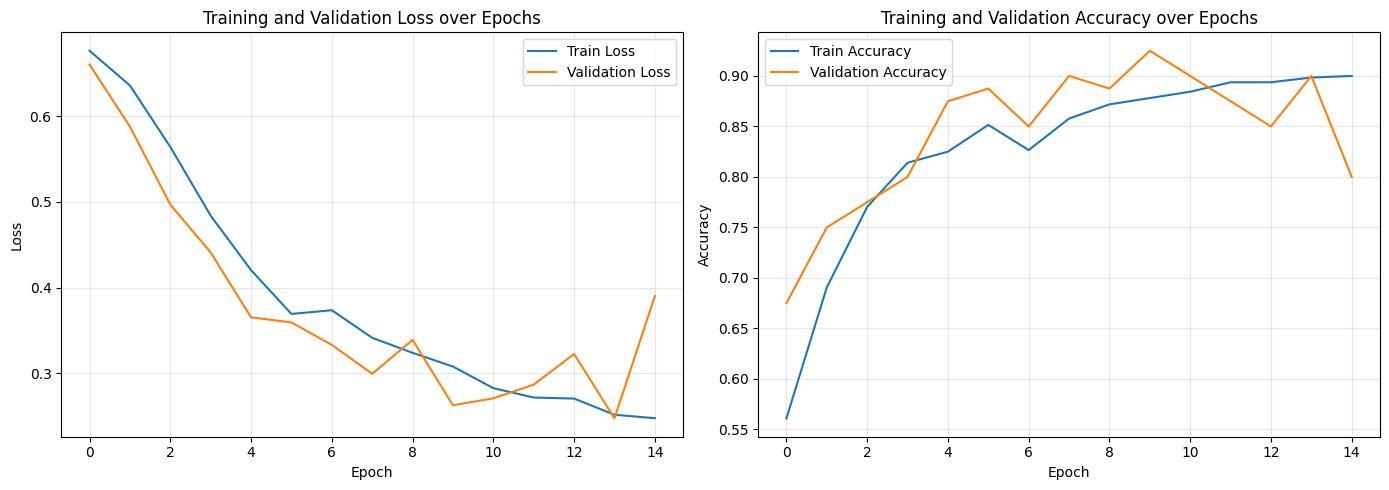

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(train_losses, label="Train Loss")
ax1.plot(val_losses,   label="Validation Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.set_title("Training and Validation Loss over Epochs")
ax1.grid(True, alpha=0.3)

ax2.plot(train_accs, label="Train Accuracy")
ax2.plot(val_accs,   label="Validation Accuracy")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.set_title("Training and Validation Accuracy over Epochs")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. הערכה על Test Set

In [10]:
test_loss, test_acc, test_preds, test_labels = evaluate(
    model, test_loader, shared_criterion, device
)

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print()
print(classification_report(test_labels, test_preds, target_names=CLASS_NAMES))

Test Loss:     0.3160
Test Accuracy: 0.8305

              precision    recall  f1-score   support

     choking       0.93      0.76      0.84        34
    laughter       0.74      0.92      0.82        25

    accuracy                           0.83        59
   macro avg       0.84      0.84      0.83        59
weighted avg       0.85      0.83      0.83        59



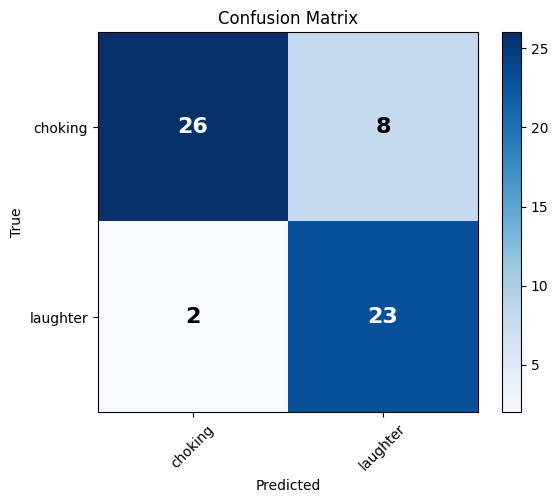

In [11]:
cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
plt.colorbar()

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

## 7. שמירת המודל

In [ ]:
SAVE_PATH = PROJECT_DIR / "audio_cnn_v4.pth"

torch.save({
    "model_state_dict": model.state_dict(),

    "class_names": CLASS_NAMES,
    "channel_names": CHANNEL_NAMES,

    "n_channels": N_CHANNELS,
    "input_shape": (N_CHANNELS, HEIGHT, WIDTH),

    "norm_mean": norm_stats["mean"],
    "norm_std": norm_stats["std"],

    "model_type": "MultiBranchAudioCNN",
    "branch_dim": 32
}, SAVE_PATH)

print("Model saved to:", SAVE_PATH)

Model saved to: /content/drive/MyDrive/פרוייקט גמר- זיהוי רעשים/audio_cnn_v4_final.pth


## 8. ארכיטקטורה נוספת — RNN (BiLSTM)

ה-CNN מסתכל על הספקטרוגרמה כתמונה. ה-RNN מתייחס אליה כרצף על ציר הזמן: בכל צעד-זמן (frame) הוא מקבל וקטור תכונות ולומד את **הדינמיקה הזמנית** — איך האנרגיה, הגובה והמרקם מתפתחים לאורך הזמן. זה טבעי להבחנה בין חנק לצחוק, שהיא במהותה תבנית קצב/חזרתיות לאורך הזמן.

זרימת המודל:
- קלט `(B, C, H, W)` ← רצף באורך `W`, בכל פריים וקטור בגודל `C·H`
- **Frame embedding** — הטלה לינארית של כל פריים למימד נמוך
- **BiLSTM** דו-כיווני שמעבד את הרצף בשני הכיוונים
- **Mean-pooling** על ציר הזמן ← מסווג קטן

**השוואה הוגנת.** שני המודלים עוברים את אותו פרוטוקול אימון בדיוק דרך הפונקציה `run_training`: אותה פונקציית loss משוקללת, אותו optimizer, אותו scheduler, אותו gradient clipping, אותו early stopping, אותו seed ואותו סדר batches. המשתנה היחיד הוא הארכיטקטורה עצמה, ולכן כל הבדל בביצועים ניתן לייחוס לארכיטקטורה ולא לכיוונון. המתג `USE_FREQ_POOL` שולט רק במבנה הקלט הפנימי של ה-RNN והוא חלק מהארכיטקטורה, לא מפרוטוקול האימון.

In [ ]:
class AudioBiLSTM(nn.Module):
    """
    ארכיטקטורת RNN להשוואה מול ה-CNN.

    מתייחסת לטנסור כרצף על ציר הזמן:
        (B, C, H, W) -> רצף באורך W.

    freq_pool=False : בכל פריים וקטור בגודל C*H (שומר את כל פירוט התדר).
    freq_pool=True  : ממצעים על ציר התדר -> בכל פריים וקטור בגודל C בלבד.
                      מקטין דרמטית את מספר הפרמטרים -> פחות overfitting בדאטה קטן.

    שלבים: Frame embedding -> BiLSTM -> Mean-pool על הזמן -> Classifier.
    """
    def __init__(self, n_channels, height, num_classes=2,
                 embed_dim=64, hidden_size=64, num_layers=1,
                 dropout=0.3, freq_pool=False):
        super().__init__()
        self.freq_pool = freq_pool
        self.input_dim = n_channels if freq_pool else n_channels * height

        self.frame_norm = nn.LayerNorm(self.input_dim)
        self.frame_embed = nn.Sequential(
            nn.Linear(self.input_dim, embed_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 48),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(48, num_classes),
        )

    def forward(self, x):
        B, C, H, W = x.shape
        if self.freq_pool:
            x = x.mean(dim=2)            # ממצעים על התדר -> (B, C, W)
            x = x.permute(0, 2, 1)       # -> (B, W, C)
        else:
            x = x.permute(0, 3, 1, 2).reshape(B, W, C * H)  # -> (B, W, C*H)

        x = self.frame_norm(x)
        x = self.frame_embed(x)          # (B, W, embed_dim)
        out, _ = self.lstm(x)            # (B, W, 2*hidden_size)
        out = out.mean(dim=1)            # mean-pool על הזמן
        return self.classifier(out)


# מתג ארכיטקטורה: הפכי ל-True אם רואים overfitting (פער train/val גדול)
USE_FREQ_POOL = False

# הדפסת מספר פרמטרים בלבד; המודל ייווצר מחדש תחת seed קבוע בתא האימון
_tmp = AudioBiLSTM(N_CHANNELS, HEIGHT, NUM_CLASSES, freq_pool=USE_FREQ_POOL)
_p = sum(p.numel() for p in _tmp.parameters() if p.requires_grad)
print("RNN (BiLSTM) trainable parameters:", f"{_p:,}")
print("freq_pool:", USE_FREQ_POOL, "| input dim per frame:", _tmp.input_dim)
del _tmp

## 8.1 אימון ה-RNN

שני המודלים עוברים את אותו פרוטוקול בדיוק דרך `run_training`: אותה פונקציית loss משוקללת, אותו optimizer ו-scheduler, אותו gradient clipping, אותו early stopping ואותו seed. בכל epoch מנוטר גם פער train/val כדי לזהות overfitting מוקדם. ההבדל היחיד בין הריצות הוא הארכיטקטורה.

In [ ]:
# ===== RNN — אותו פרוטוקול אימון בדיוק כמו ה-CNN =====
set_seed(TrainConfig.seed)
rnn_model = AudioBiLSTM(
    n_channels=N_CHANNELS,
    height=HEIGHT,
    num_classes=NUM_CLASSES,
    freq_pool=USE_FREQ_POOL,
).to(device)

rnn_hist, rnn_best_epoch = run_training(
    rnn_model,
    shared_criterion,
    TrainConfig,
    PROJECT_DIR / "best_audio_rnn_v4.pth",
)

# שמות תואמים לתאי הגרפים והאבחון הקיימים (סעיפים 8.2, 8.3)
rnn_train_losses, rnn_val_losses = rnn_hist["train_loss"], rnn_hist["val_loss"]
rnn_train_accs,   rnn_val_accs   = rnn_hist["train_acc"],  rnn_hist["val_acc"]

## 8.2 אבחון overfitting

מסכם את הפער בין train ל-validation. אם הפער גדול — המודל משנן ולא מכליל, והתא יציע בדיוק איזה מנוף להפעיל.

In [ ]:
final_gap = rnn_train_accs[-1] - rnn_val_accs[-1]
best_val_acc = max(rnn_val_accs)
best_val_ep  = rnn_val_accs.index(best_val_acc) + 1
max_gap = max(t - v for t, v in zip(rnn_train_accs, rnn_val_accs))

print(f"Best Val Accuracy:   {best_val_acc:.3f}  (epoch {best_val_ep})")
print(f"Final train/val gap: {final_gap:+.3f}")
print(f"Max train/val gap:   {max_gap:+.3f}")
print("-" * 50)

if max_gap > 0.20:
    print("⚠️  overfitting משמעותי. מנופים לפי סדר עוצמה:")
    print("   1. USE_FREQ_POOL = True  (בתא המודל) — מקטין דרמטית פרמטרים")
    print("   2. embed_dim=32, hidden_size=32 — מודל קטן יותר")
    print("   3. dropout=0.5 — רגולריזציה חזקה יותר")
    print("   הריצי שוב את תא המודל ואת תא האימון אחרי השינוי.")
elif max_gap > 0.12:
    print("⚠️  overfitting קל. כנראה תקין, אך שווה לנסות USE_FREQ_POOL=True ולהשוות.")
else:
    print("✅  הפער סביר — המודל מכליל יפה.")


## 8.3 גרפים — RNN

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(rnn_train_losses, label="Train Loss")
ax1.plot(rnn_val_losses,   label="Validation Loss")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax1.legend(); ax1.set_title("RNN — Loss over Epochs")
ax1.grid(True, alpha=0.3)

ax2.plot(rnn_train_accs, label="Train Accuracy")
ax2.plot(rnn_val_accs,   label="Validation Accuracy")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Accuracy")
ax2.legend(); ax2.set_title("RNN — Accuracy over Epochs")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 8.4 הערכת ה-RNN על Test Set

In [ ]:
rnn_test_loss, rnn_test_acc, rnn_test_preds, rnn_test_labels = evaluate(
    rnn_model, test_loader, shared_criterion, device
)

print(f"RNN Test Loss:     {rnn_test_loss:.4f}")
print(f"RNN Test Accuracy: {rnn_test_acc:.4f}")
print()
print(classification_report(rnn_test_labels, rnn_test_preds, target_names=CLASS_NAMES))

In [ ]:
cm = confusion_matrix(rnn_test_labels, rnn_test_preds)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("RNN — Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45)
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
plt.colorbar()

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black",
                 fontsize=16, fontweight="bold")

plt.tight_layout()
plt.show()


## 8.5 שמירת מודל ה-RNN

In [ ]:
RNN_SAVE_PATH = PROJECT_DIR / "audio_rnn_v4.pth"

torch.save({
    "model_state_dict": rnn_model.state_dict(),
    "class_names": CLASS_NAMES,
    "channel_names": CHANNEL_NAMES,
    "n_channels": N_CHANNELS,
    "input_shape": (N_CHANNELS, HEIGHT, WIDTH),
    "norm_mean": norm_stats["mean"],
    "norm_std": norm_stats["std"],
    "model_type": "AudioBiLSTM",
    "embed_dim": 64,
    "hidden_size": 64,
    "num_layers": 1,
    "freq_pool": USE_FREQ_POOL,
}, RNN_SAVE_PATH)

print("RNN model saved to:", RNN_SAVE_PATH)


## 9. השוואה — CNN מול RNN

מריצים אחרי שהורצו גם סעיף ה-CNN (סעיפים 2–6) וגם סעיף ה-RNN (סעיף 8). משווה את ה-accuracy על ה-test set.

In [ ]:
# מצריך ש-test_acc (CNN, סעיף 6) ו-rnn_test_acc (סעיף 8.4) קיימים בזיכרון
from sklearn.metrics import f1_score

try:
    cnn_test_acc = test_acc
except NameError:
    raise NameError("הריצי קודם את תא ההערכה של ה-CNN (סעיף 6) לפני ההשוואה.")

# Macro-F1 — מדד מאוזן, חשוב כשהמחלקות לא מאוזנות
cnn_f1 = f1_score(test_labels, test_preds, average="macro")
rnn_f1 = f1_score(rnn_test_labels, rnn_test_preds, average="macro")

print(f"CNN  Test Accuracy: {cnn_test_acc:.4f} | Macro-F1: {cnn_f1:.4f}")
print(f"RNN  Test Accuracy: {rnn_test_acc:.4f} | Macro-F1: {rnn_f1:.4f}")

groups = ["CNN\n(Multi-Branch)", "RNN\n(BiLSTM)"]
acc_vals = [cnn_test_acc, rnn_test_acc]
f1_vals  = [cnn_f1, rnn_f1]
xpos = np.arange(len(groups))
w = 0.35

plt.figure(figsize=(7, 5))
b1 = plt.bar(xpos - w / 2, acc_vals, w, label="Accuracy", color="#4C72B0")
b2 = plt.bar(xpos + w / 2, f1_vals,  w, label="Macro-F1", color="#C44E52")
plt.xticks(xpos, groups)
plt.ylabel("Score"); plt.ylim(0, 1.0)
plt.title("Architecture Comparison — Test Set")
plt.grid(True, axis="y", alpha=0.3); plt.legend()

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, h + 0.02, f"{h:.3f}",
                 ha="center", va="bottom", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()